# 06 — Application au contexte fiscal marocain

**Détection d'anomalies fiscales par des techniques de l'Intelligence Artificielle :**  
**cas de la Direction Régionale des Impôts de Tétouan**

---

Les notebooks 01 à 05 construisent et valident un modèle sur **JAR2020** — 146 045 états financiers d'entreprises américaines cotées, étiquetés à partir des sanctions de la SEC.

Ce notebook répond à la question suivante : **les données dont dispose réellement une direction régionale des impôts marocaine peuvent-elles alimenter ce modèle ?**

Il déroule la chaîne complète, de la liasse fiscale déposée par le contribuable jusqu'aux motifs de signalement d'un dossier :

| Étape | Question |
|---|---|
| 1. Les données de départ | De quoi dispose l'administration ? |
| 2. Contrôles de cohérence | L'extraction est-elle exploitable ? |
| 3. La correspondance CGNC → Compustat | Les postes marocains se traduisent-ils ? |
| 4. Application du mapping | Quelle couverture obtient-on réellement ? |
| 5. La question des unités | Dirhams contre millions de dollars : que se passe-t-il ? |
| 6. Scoring | À quoi ressemble le classement produit ? |
| 7. Interprétation SHAP | Le signalement est-il actionnable par un vérificateur ? |
| 8. Robustesse | Les variables absentes de la liasse invalident-elles le résultat ? |

> ## ⚠️ Statut de ce notebook — à lire avant d'interpréter quoi que ce soit
>
> **Les données utilisées ici sont entièrement fictives.** Huit entreprises inventées de la région de Tétouan, sur trois exercices, générées par `scripts/generer_exemple_liasse.py`.
>
> Ce notebook démontre que la **chaîne de traitement fonctionne** de bout en bout sur des données au format de la liasse fiscale marocaine. Il ne démontre **rien** sur la capacité du modèle à détecter la fraude au Maroc : aucune de ces entreprises n'existe, aucune n'est étiquetée, et les scores obtenus n'ont aucune valeur d'analyse.
>
> Les données réelles de la DRI sont couvertes par le **secret professionnel (article 246 du CGI)** et aucun jeu marocain étiqueté n'est public. Voir `docs/01_cadrage_methodologique.md` §2.
>
> Pour une illustration sur données authentiques, la piste ouverte est celle des sociétés cotées à la Bourse de Casablanca (états financiers publics via l'AMMC) — voir `docs/02_mapping_liasse_fiscale.md` §9.

In [1]:
import sys
from pathlib import Path

# Rend `src/` importable, que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd()
if not (RACINE / "src").is_dir():
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import io

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.feature_engineering import add_fiscal_features
from src.inference import explain_row, load_model, score_with_diagnostics
from src.liasse_mapping import (
    mapper_liasse,
    table_correspondance,
    verifier_liasse,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

MODELE, META = load_model()
print(
    f"Modèle chargé : {META['n_features']} variables "
    f"({len(META['temporal_features'])} de trajectoire, "
    f"{len(META['fiscal_features'])} ratios fiscaux métier)"
)

Modèle chargé : 54 variables (20 de trajectoire, 6 ratios fiscaux métier)


---
## 1. Le point de départ : ce dont dispose l'administration

La **liasse fiscale** déposée par chaque contribuable soumis à l'IS comporte, entre autres, le **bilan** (tableaux n° 1 et 2) et le **compte de produits et charges** (tableau n° 3), établis selon le **Code Général de Normalisation Comptable**.

Depuis le 1<sup>er</sup> janvier 2017, la télédéclaration est obligatoire : ces documents arrivent à la DGI sous forme **structurée**, via le portail SIMPL. La matière première du modèle est donc déjà numérique et déjà détenue par l'administration — ce qui manque n'est pas la donnée d'entrée, mais l'étiquette.

In [2]:
CHEMIN_LIASSES = RACINE / "dashboard" / "exemple_liasse_marocaine.csv"
liasses = pd.read_csv(CHEMIN_LIASSES)

print(
    f"{len(liasses)} lignes — "
    f"{liasses['identifiant_fiscal'].nunique()} contribuables × "
    f"{liasses['exercice'].nunique()} exercices\n"
)
print("Secteurs représentés :")
print(liasses["secteur"].value_counts().to_string())

liasses[[
    "raison_sociale", "commune", "exercice", "total_actif",
    "chiffre_affaires", "resultat_net_exercice", "impots_sur_les_resultats",
]].head(6)

24 lignes — 8 contribuables × 3 exercices

Secteurs représentés :
secteur
Industrie agroalimentaire      3
Textile et habillement         3
Batiment et travaux publics    3
Commerce de gros               3
Hebergement et restauration    3
Transport et logistique        3
Peche et transformation        3
Negoce de materiaux            3


,raison_sociale,commune,exercice,total_actif,chiffre_affaires,resultat_net_exercice,impots_sur_les_resultats
0,CONSERVERIE DU DETROIT SA,Tetouan,2021,28312353.37,42497367.43,2812326.37,692905.82
1,CONSERVERIE DU DETROIT SA,Tetouan,2022,30287008.60,45461361.55,2904192.63,938832.02
2,CONSERVERIE DU DETROIT SA,Tetouan,2023,33629875.36,50479066.54,3419539.76,1009988.22
3,TEXTILE RIF SARL,Tetouan,2021,13616034.48,18563305.69,1051383.06,299240.05
4,TEXTILE RIF SARL,Tetouan,2022,14098312.19,19220814.94,1138061.04,359458.80
5,TEXTILE RIF SARL,Tetouan,2023,14914176.18,20333116.22,951424.77,274643.82


---
## 2. Contrôles de cohérence comptable

Avant tout scoring. Un fichier dont le bilan ne s'équilibre pas, ou qui comporte des doublons (contribuable, exercice), produirait des scores ininterprétables — autant le dire tout de suite plutôt que de commenter des résultats construits sur une extraction fausse.

Ces contrôles portent sur la **qualité de l'extraction**. Ils ne constituent en aucun cas des indices de fraude.

In [3]:
diagnostic = verifier_liasse(liasses)

print("Scorable             :", diagnostic["scorable"])
print("Anomalies bloquantes :", diagnostic["anomalies"] or "aucune")
print("Avertissements       :", diagnostic["avertissements"] or "aucun")

# Vérification manuelle de l'équilibre du bilan sur la première ligne
ligne = liasses.iloc[0]
passif = (
    ligne["total_capitaux_propres"] + ligne["capitaux_propres_assimiles"]
    + ligne["dettes_financement"] + ligne["provisions_durables"]
    + ligne["total_passif_circulant"] + ligne["tresorerie_passif"]
)
print(f"\nContrôle manuel — {ligne['raison_sociale']} ({ligne['exercice']}) :")
print(f"  total actif  = {ligne['total_actif']:>18,.2f} MAD".replace(",", " "))
print(f"  total passif = {passif:>18,.2f} MAD".replace(",", " "))
print(f"  écart        = {abs(passif - ligne['total_actif']):>18,.2f} MAD".replace(",", " "))

Scorable             : True
Anomalies bloquantes : aucune
Avertissements       : aucun

Contrôle manuel — CONSERVERIE DU DETROIT SA (2021) :
  total actif  =      28 312 353.37 MAD
  total passif =      28 312 353.36 MAD
  écart        =               0.01 MAD


---
## 3. La correspondance CGNC → variables du modèle

Le modèle attend 28 variables nommées selon la nomenclature **Compustat** (`act`, `ceq`, `sale`…). Un vérificateur, lui, connaît les postes du bilan et du CPC marocains. La table de correspondance de `src/liasse_mapping.py` fait le pont.

Chaque correspondance porte son **degré de fidélité**. Un tableau qui prétendrait à l'exactitude sur les 28 variables serait malhonnête :

- 🟢 **directe** — le poste marocain recouvre exactement la notion Compustat ;
- 🔵 **agrégat** — reconstruction par somme ou différence de postes exacts ;
- 🟠 **approximation** — le concept diffère, l'écart est identifié et documenté ;
- ⚪ **indisponible** — absent de la liasse, laissé à `NaN`.

In [4]:
correspondance = table_correspondance()

print("Répartition des 28 correspondances par degré de fidélité :")
print(correspondance["Fidélité"].value_counts().to_string())
print(
    "\n→ 22 des 28 variables (directes + agrégats + `pstk` par convention)"
    "\n  sont reconstituables à partir de la seule liasse fiscale."
)

correspondance[[
    "Variable modèle", "Poste de la liasse marocaine", "Tableau", "Fidélité",
]].head(14)

Répartition des 28 correspondances par degré de fidélité :
Fidélité
directe          14
agregat           7
approximation     5
indisponible      2

→ 22 des 28 variables (directes + agrégats + `pstk` par convention)
  sont reconstituables à partir de la seule liasse fiscale.


,Variable modèle,Poste de la liasse marocaine,Tableau,Fidélité
0,act,TOTAL II (actif circulant hors trésorerie) + T...,Bilan — Actif,agregat
1,ap,Fournisseurs et comptes rattachés,Bilan — Passif (dettes du passif circulant),directe
2,at,TOTAL GÉNÉRAL ACTIF (I + II + III),Bilan — Actif,directe
3,ceq,TOTAL DES CAPITAUX PROPRES (A),Bilan — Passif (financement permanent),directe
4,che,TOTAL III (trésorerie-actif) + Titres et valeu...,Bilan — Actif,agregat
5,cogs,Achats revendus de marchandises + Achats conso...,CPC — charges d'exploitation,agregat
6,csho,Nombre de titres composant le capital social (...,ETIC — état des informations complémentaires,approximation
7,dlc,TOTAL V (trésorerie-passif) + part des dettes ...,Bilan — Passif,agregat
8,dltis,Augmentation des dettes de financement (ressou...,Tableau de financement (tableau n°5),approximation
9,dltt,Dettes de financement (C),Bilan — Passif (financement permanent),directe


### Les quatre variables sans équivalent

| Variable | Nature | Pourquoi elle manque |
|---|---|---|
| `prcc_f` | Cours de bourse à la clôture | N'existe que pour les ~75 sociétés cotées |
| `csho` | Nombre de titres | Figure à l'ETIC, rarement renseigné |
| `dltis` | Augmentation des dettes de financement | Variable de **flux** — tableau de financement |
| `sstk` | Augmentations de capital | Variable de **flux** — tableau de financement |

**Elles sont laissées à `NaN`, jamais remplies par des zéros.** La distinction est décisive : XGBoost traite nativement les valeurs manquantes en apprenant, pour chaque nœud, la direction par défaut des observations dont la valeur est absente. Un `NaN` signifie donc « information non disponible ». Un `0`, lui, affirmerait que l'entreprise n'a réalisé aucune augmentation de capital et que son action ne vaut rien — deux affirmations fausses, placées de surcroît à un endroit précis de la distribution d'entraînement.

La section 8 mesure l'effet réel de ces absences.

---
## 4. Application du mapping

In [5]:
# Cours Bank Al-Maghrib à la clôture de l'exercice considéré.
# À renseigner exercice par exercice pour tout travail sérieux.
TAUX_MAD_USD = 9.85

donnees_modele, rapport = mapper_liasse(
    liasses, unite="dirhams", mad_par_usd=TAUX_MAD_USD, convertir_en_usd=True,
)

print(f"Variables reconstituées   : {rapport['n_variables_renseignees']}/28 "
      f"({rapport['taux_couverture_global_pct']} %)")
print(f"Variables sans équivalent : {', '.join(rapport['variables_vides'])}")
print(f"Conversion appliquée      : {rapport['unite_saisie']} → {rapport['devise_sortie']}")
print(f"Colonnes non reconnues    : {rapport['colonnes_ignorees'] or 'aucune'}")

donnees_modele[[
    "raison_sociale", "fyear", "at", "sale", "ni", "txt", "ceq", "lt", "ib", "pstk", "prcc_f",
]].head(6).round(3)

Variables reconstituées   : 24/28 (85.7 %)
Variables sans équivalent : csho, dltis, sstk, prcc_f
Conversion appliquée      : dirhams → millions USD
Colonnes non reconnues    : aucune


,raison_sociale,fyear,at,sale,ni,txt,ceq,lt,ib,pstk,prcc_f
0,CONSERVERIE DU DETROIT SA,2021,2.874,4.314,0.286,0.070,1.272,1.581,0.279,0.0,NaN
1,CONSERVERIE DU DETROIT SA,2022,3.075,4.615,0.295,0.095,1.733,1.313,0.308,0.0,NaN
2,CONSERVERIE DU DETROIT SA,2023,3.414,5.125,0.347,0.103,1.893,1.512,0.373,0.0,NaN
3,TEXTILE RIF SARL,2021,1.382,1.885,0.107,0.030,0.739,0.641,0.097,0.0,NaN
4,TEXTILE RIF SARL,2022,1.431,1.951,0.116,0.036,0.784,0.621,0.112,0.0,NaN
5,TEXTILE RIF SARL,2023,1.514,2.064,0.097,0.028,0.628,0.876,0.108,0.0,NaN


In [6]:
# Couverture variable par variable — ce que le rapport permet de tracer.
detail = rapport["detail"]
detail[detail["taux_couverture_pct"] < 100][[
    "variable", "poste_liasse", "fidelite", "taux_couverture_pct",
]]

,variable,poste_liasse,fidelite,taux_couverture_pct
6,csho,Nombre de titres composant le capital social (...,approximation,0.0
8,dltis,Augmentation des dettes de financement (ressou...,approximation,0.0
23,sstk,"Augmentations de capital, apports (ressources ...",approximation,0.0
27,prcc_f,"— (donnée de marché, hors liasse)",indisponible,0.0


---
## 5. La question des unités

JAR2020 est libellé en **millions de dollars**. Une liasse marocaine est déposée en **dirhams**. L'écart d'échelle est de l'ordre de 10⁷.

Cela serait sans conséquence si le modèle n'utilisait que des ratios. Ce n'est pas le cas : **48 des 54 variables sont des variables de niveau** (28 postes en log signé + 20 variations). Les arbres de décision découpant sur des seuils absolus, une conversion erronée déplace les dossiers hors de la distribution d'entraînement.

Les **6 ratios fiscaux métier** sont en revanche invariants d'échelle. La cellule suivante le vérifie.

In [7]:
en_usd, _ = mapper_liasse(liasses, unite="dirhams", mad_par_usd=TAUX_MAD_USD,
                          convertir_en_usd=True)
en_mad, _ = mapper_liasse(liasses, unite="dirhams", convertir_en_usd=False)

ratios_usd, noms_ratios = add_fiscal_features(en_usd)
ratios_mad, _ = add_fiscal_features(en_mad)
ratios_usd = ratios_usd.sort_index()
ratios_mad = ratios_mad.sort_index()

ecart_max = (ratios_usd[noms_ratios] - ratios_mad[noms_ratios]).abs().max().max()
print(f"Écart maximal sur les 6 ratios fiscaux entre les deux devises : {ecart_max:.2e}")
print("→ invariance d'échelle confirmée\n")

pd.DataFrame({
    "at — millions USD": ratios_usd["at"],
    "at — millions MAD": ratios_mad["at"],
    "effective_tax_rate (USD)": ratios_usd["effective_tax_rate"],
    "effective_tax_rate (MAD)": ratios_mad["effective_tax_rate"],
    "receivables_ratio (USD)": ratios_usd["receivables_ratio"],
    "receivables_ratio (MAD)": ratios_mad["receivables_ratio"],
}).head(5).round(4)

Écart maximal sur les 6 ratios fiscaux entre les deux devises : 1.12e-05
→ invariance d'échelle confirmée



,at — millions USD,at — millions MAD,effective_tax_rate (USD),effective_tax_rate (MAD),receivables_ratio (USD),receivables_ratio (MAD)
0,2.8744,28.3124,0.2013,0.2013,0.1185,0.1185
1,3.0748,30.2870,0.2365,0.2365,0.1370,0.1370
2,3.4142,33.6299,0.2156,0.2156,0.1494,0.1494
3,1.3823,13.6160,0.2386,0.2386,0.1345,0.1345
4,1.4313,14.0983,0.2460,0.2460,0.1453,0.1453


C'est une propriété rassurante : la part la plus directement interprétable du modèle — celle qui parle le langage du vérificateur — est aussi celle qui résiste le mieux au changement de contexte.

---
## 6. Scoring : le classement de risque

La question opérationnelle d'une direction régionale n'est jamais « qui fraude ? » mais « **par lesquels commencer ?** ». Le modèle ordonne le portefeuille ; il ne rend pas de verdict.

In [8]:
resultat = score_with_diagnostics(donnees_modele)
classement = resultat["scored"]

print(f"{resultat['n_rows']} dossiers classés")
print(f"Couverture des variables de trajectoire : "
      f"{resultat['coverage']['available_pct']:.0f} % "
      f"({resultat['coverage']['rows_with_history']} lignes avec historique)")

classement[[
    "risk_rank", "raison_sociale", "secteur", "commune", "fyear",
    "risk_score", "risk_percentile",
]].head(10).round(4)

24 dossiers classés
Couverture des variables de trajectoire : 50 % (16 lignes avec historique)


,risk_rank,raison_sociale,secteur,commune,fyear,risk_score,risk_percentile
7,1,BTP MARTIL CONSTRUCTION SA,Batiment et travaux publics,Martil,2022,0.6763,100.0000
6,2,BTP MARTIL CONSTRUCTION SA,Batiment et travaux publics,Martil,2021,0.6737,95.8333
13,3,HOTELIERE CABO NEGRO SA,Hebergement et restauration,M'diq,2022,0.6256,91.6667
9,4,DISTRIBUTION NORD SARL,Commerce de gros,Tetouan,2021,0.6180,87.5000
14,5,HOTELIERE CABO NEGRO SA,Hebergement et restauration,M'diq,2023,0.6096,83.3333
12,6,HOTELIERE CABO NEGRO SA,Hebergement et restauration,M'diq,2021,0.5645,79.1667
11,7,DISTRIBUTION NORD SARL,Commerce de gros,Tetouan,2023,0.5029,75.0000
16,8,TRANSPORT LOGISTIQUE TANGEROISE SARL,Transport et logistique,Fnideq,2022,0.4997,70.8333
8,9,BTP MARTIL CONSTRUCTION SA,Batiment et travaux publics,Martil,2023,0.4973,66.6667
10,10,DISTRIBUTION NORD SARL,Commerce de gros,Tetouan,2022,0.4865,62.5000


In [9]:
print("Distribution des scores sur ce lot :")
print(classement["risk_score"].describe().round(3).to_string())

print(
    "\n⚠️  CES SCORES NE SONT PAS DES PROBABILITÉS.\n"
    f"    Le modèle est entraîné avec scale_pos_weight ≈ {META['best_spw']:.0f} pour compenser\n"
    "    un déséquilibre de 150 pour 1 : les probabilités produites sont mécaniquement\n"
    "    gonflées. Les 4 variables absentes de la liasse déplacent encore le niveau\n"
    "    vers le haut (cf. section 8).\n\n"
    "    Un score de 0,70 ne signifie PAS « 70 % de chances de fraude ».\n"
    "    Seul le CLASSEMENT (risk_rank) doit être exploité — jamais un seuil absolu."
)

Distribution des scores sur ce lot :
count    24.000
mean      0.438
std       0.137
min       0.221
25%       0.345
50%       0.399
75%       0.518
max       0.676

⚠️  CES SCORES NE SONT PAS DES PROBABILITÉS.
    Le modèle est entraîné avec scale_pos_weight ≈ 121 pour compenser
    un déséquilibre de 150 pour 1 : les probabilités produites sont mécaniquement
    gonflées. Les 4 variables absentes de la liasse déplacent encore le niveau
    vers le haut (cf. section 8).

    Un score de 0,70 ne signifie PAS « 70 % de chances de fraude ».
    Seul le CLASSEMENT (risk_rank) doit être exploité — jamais un seuil absolu.


---
## 7. Interprétation : pourquoi ce dossier est-il signalé ?

Une liste de matricules classés sans justification est inexploitable. Un chef de brigade doit pouvoir dire pourquoi il retient un dossier, et un vérificateur doit savoir où regarder en priorité.

SHAP décompose le score en contributions par variable : ce qui l'a poussé vers le haut, et ce qui l'a retenu vers le bas.

In [10]:
DOSSIER = 0  # le mieux classé

cible = classement.iloc[[DOSSIER]]
print(f"Dossier analysé : {cible['raison_sociale'].iloc[0]}")
print(f"  secteur  : {cible['secteur'].iloc[0]}")
print(f"  exercice : {int(cible['fyear'].iloc[0])}")
print(f"  score    : {cible['risk_score'].iloc[0]:.4f} "
      f"(rang {int(cible['risk_rank'].iloc[0])})")

contributions = explain_row(classement.reset_index(drop=True), DOSSIER, top_n=12)
contributions.round(4)

Dossier analysé : BTP MARTIL CONSTRUCTION SA
  secteur  : Batiment et travaux publics
  exercice : 2022
  score    : 0.6763 (rang 1)


,feature,valeur,contribution_shap,effet
0,ppegt_log,2.5882,0.5179,augmente le risque
1,prcc_f_log,NaN,0.4349,augmente le risque
2,csho_log,NaN,0.3852,augmente le risque
3,sale_log,2.6709,-0.2499,diminue le risque
4,che_log,0.4466,0.2499,augmente le risque
5,act_log,2.0453,-0.2036,diminue le risque
6,receivables_ratio,0.2331,0.2028,augmente le risque
7,sstk_log,NaN,0.1478,augmente le risque
8,ivst_log,0.1012,-0.1316,diminue le risque
9,rect_log,1.4196,-0.1257,diminue le risque


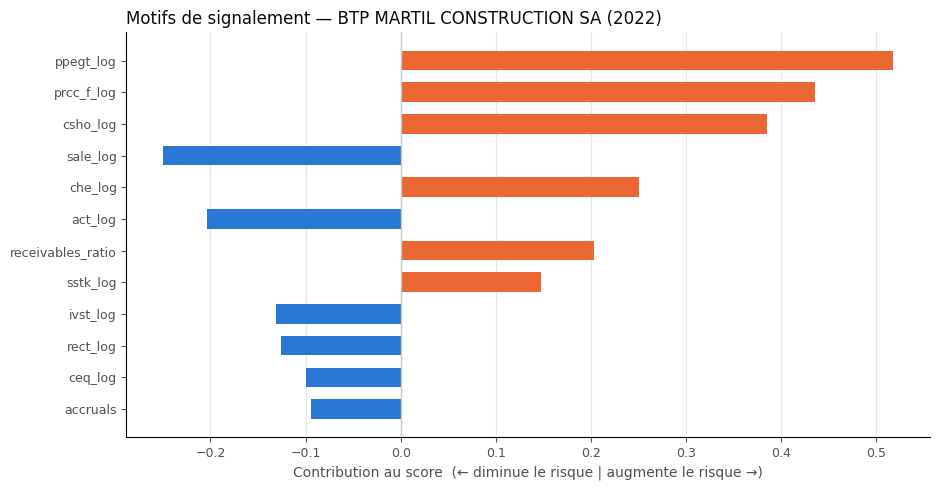

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 5))

c = contributions.iloc[::-1]
couleurs = ["#eb6834" if v > 0 else "#2a78d6" for v in c["contribution_shap"]]
ax.barh(c["feature"], c["contribution_shap"], color=couleurs, height=0.62)
ax.axvline(0, color="#c9c9c4", linewidth=1)
ax.set_xlabel("Contribution au score  (← diminue le risque | augmente le risque →)",
              color="#52514e")
ax.set_title(f"Motifs de signalement — {cible['raison_sociale'].iloc[0]} "
             f"({int(cible['fyear'].iloc[0])})", loc="left", color="#0b0b0b")
for cote in ("top", "right"):
    ax.spines[cote].set_visible(False)
ax.grid(True, axis="x", color="#e8e8e4", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors="#52514e", labelsize=9)
fig.tight_layout()
plt.show()

### Traduire les variables en postes de la liasse

`ppegt_log_d1` ne dit rien à un vérificateur. « Variation sur un exercice des immobilisations corporelles brutes » lui dit où regarder. C'est cette traduction qui rend l'alerte actionnable — et qui autorise le désaccord : un vérificateur connaissant une explication légitime (litige commercial, report déficitaire, changement de méthode) peut écarter le dossier en connaissance de cause.

In [12]:
def poste_dorigine(variable: str) -> str:
    """Remonte d'une variable du modèle au poste de la liasse dont elle dérive."""
    base = variable
    for suffixe in ("_log_d1", "_log_d2", "_log"):
        if base.endswith(suffixe):
            base = base[: -len(suffixe)]
            break
    ligne = correspondance[correspondance["Variable modèle"] == base]
    if ligne.empty:
        return "— ratio calculé, pas un poste de la liasse —"
    return ligne["Poste de la liasse marocaine"].iloc[0]


lecture = contributions[["feature", "contribution_shap", "effet"]].copy()
lecture["poste de la liasse"] = lecture["feature"].map(poste_dorigine)
lecture.rename(columns={
    "feature": "variable", "contribution_shap": "contribution",
}).round(4)

,variable,contribution,effet,poste de la liasse
0,ppegt_log,0.5179,augmente le risque,Immobilisations corporelles — colonne BRUT
1,prcc_f_log,0.4349,augmente le risque,"— (donnée de marché, hors liasse)"
2,csho_log,0.3852,augmente le risque,Nombre de titres composant le capital social (...
3,sale_log,-0.2499,diminue le risque,CHIFFRE D'AFFAIRES (ventes de marchandises + v...
4,che_log,0.2499,augmente le risque,TOTAL III (trésorerie-actif) + Titres et valeu...
5,act_log,-0.2036,diminue le risque,TOTAL II (actif circulant hors trésorerie) + T...
6,receivables_ratio,0.2028,augmente le risque,"— ratio calculé, pas un poste de la liasse —"
7,sstk_log,0.1478,augmente le risque,"Augmentations de capital, apports (ressources ..."
8,ivst_log,-0.1316,diminue le risque,Titres et valeurs de placement (H)
9,rect_log,-0.1257,diminue le risque,Créances de l'actif circulant (G)


---
## 8. Robustesse : les variables absentes invalident-elles le résultat ?

La question n'est pas rhétorique. L'analyse SHAP ci-dessus fait apparaître `prcc_f` et `csho` **parmi les plus forts contributeurs au score** — alors même qu'ils sont vides. Le modèle les route vers la branche par défaut apprise à l'entraînement, ce qui déplace le score.

**Protocole.** Scorer deux fois les mêmes observations JAR2020 hors échantillon d'entraînement : une fois complètes, une fois avec les 4 variables forcées à `NaN` — c'est-à-dire dans la situation marocaine exacte.

Script reproductible : `python scripts/robustesse_variables_absentes.py`

In [13]:
CHEMIN_ROBUSTESSE = RACINE / "reports" / "robustesse_variables_absentes.csv"

if CHEMIN_ROBUSTESSE.exists():
    # Le fichier contient deux blocs séparés par des lignes de commentaire.
    lignes_csv = [
        l for l in CHEMIN_ROBUSTESSE.read_text(encoding="utf-8-sig").splitlines()
        if l and not l.startswith("#")
    ]
    resume = pd.read_csv(io.StringIO("\n".join(lignes_csv[:2])))
    budgets = pd.read_csv(io.StringIO("\n".join(lignes_csv[2:])))

    r = resume.iloc[0]
    print(f"Échantillon : {int(r['n_observations']):,} lignes ({r['periode']}), "
          f"{int(r['n_fraudes'])} fraudes étiquetées\n".replace(",", " "))
    print(f"  Score moyen          : {r['score_moyen_complet']:.3f} "
          f"→ {r['score_moyen_degrade']:.3f}  ({r['decalage_score_moyen']:+.3f})")
    print(f"  Corrélation de rang  : Spearman {r['spearman']:.3f}, "
          f"Kendall {r['kendall']:.3f}")
    print(f"  AUC-ROC              : {r['auc_roc_complet']:.3f} "
          f"→ {r['auc_roc_degrade']:.3f}")
    display(budgets)
else:
    print("Résultats absents. Exécutez d'abord :")
    print("    python scripts/robustesse_variables_absentes.py")
    print("(nécessite data/raw/data_FraudDetection_JAR2020.csv)")

Échantillon : 16 904 lignes (2012-2014)  34 fraudes étiquetées

  Score moyen          : 0.264 → 0.470  (+0.206)
  Corrélation de rang  : Spearman 0.865, Kendall 0.679
  AUC-ROC              : 0.714 → 0.712


,budget_pct,n_dossiers,recouvrement_pct,rappel_complet_pct,rappel_degrade_pct,ecart_rappel_pts
0,1,170,51.2,0.0,2.9,2.9
1,5,846,58.6,8.8,8.8,0.0
2,10,1691,61.9,17.6,17.6,0.0
3,20,3381,66.4,47.1,41.2,-5.9


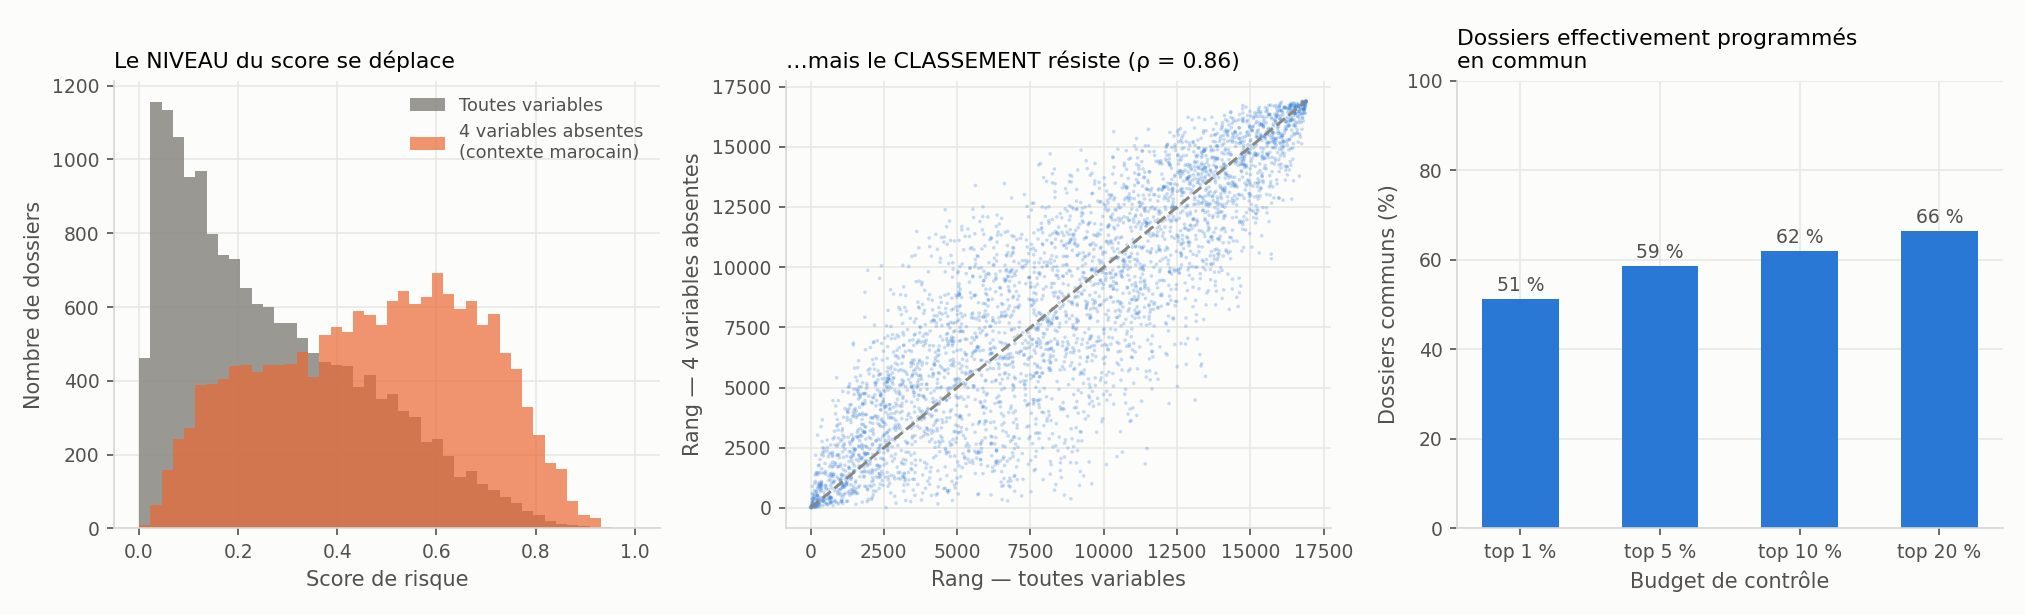

In [14]:
from IPython.display import Image, display

FIGURE_ROBUSTESSE = RACINE / "reports" / "figures" / "06_robustesse_variables_absentes.png"
if FIGURE_ROBUSTESSE.exists():
    display(Image(str(FIGURE_ROBUSTESSE)))
else:
    print("Figure absente — exécutez scripts/robustesse_variables_absentes.py")

### Lecture des résultats

| Constat | Portée |
|---|---|
| 🟢 Le **classement** résiste — Spearman 0,865, AUC-ROC 0,714 → 0,712 | Les 4 variables manquant à *toutes* les lignes, leur effet est largement commun et s'annule au classement |
| 🔴 Le **niveau** du score est fortement déplacé — moyenne 0,264 → 0,471 | Tout seuil fixe calibré sur données complètes serait inopérant : il déclencherait un signalement quasi général |
| 🟠 À budget fixé, seulement **51 à 66 % des mêmes dossiers** sont programmés | La méthode se transpose ; la liste de travail nominative, non |

**Trois conséquences pratiques :**

1. Les absences **ne sont pas rédhibitoires**.
2. Le dispositif doit s'utiliser **exclusivement en rang** (top *k* %), jamais par seuil absolu.
3. Lors d'un réentraînement sur données marocaines, ces 4 variables devront être **retirées du jeu** plutôt que laissées vides : le modèle cesserait alors de leur consacrer de la capacité prédictive et récupérerait le décalage de niveau observé ici.

---
## 9. Conclusion

### Ce que ce notebook établit

1. **La liasse fiscale marocaine alimente le modèle.** 22 des 28 variables sont reconstituables à partir des seuls bilan et CPC, avec une couverture effective de 85,7 %.
2. **La chaîne fonctionne de bout en bout** : contrôles de cohérence → correspondance CGNC/Compustat → mise à l'échelle → scoring → motifs de signalement traduits en postes de la liasse.
3. **Les absences ont été mesurées, pas supposées.** Le classement résiste ; le niveau du score non.
4. **Le résultat est interprétable par un fiscaliste** : chaque variable contributive se rattache à un poste identifiable, et les 6 ratios métier sont invariants d'échelle.

### Ce qu'il n'établit pas

Rien sur la capacité du modèle à détecter la fraude au Maroc. Les données sont fictives et non étiquetées : **sans vérité terrain, un score élevé n'est qu'un score élevé.**

### Ce qu'il resterait à faire

| Étape | Responsable |
|---|---|
| Constituer un jeu étiqueté interne (liasses × issue définitive des vérifications) | DGI / DRI |
| Traiter le biais de sélection des dossiers déjà contrôlés | DGI / DRI |
| Réentraîner, en retirant les 4 variables hors liasse | DGI / DRI |
| Évaluer à budget de contrôle constant, contre la programmation actuelle | DRI |
| Formalités CNDP et validation juridique | DGI |

Protocole détaillé : `docs/01_cadrage_methodologique.md` §6 · Scénario opérationnel : `docs/03_deploiement_DRI_Tetouan.md`

---

> **Rappel.** Un score de risque n'a **aucune valeur probante**. Il n'est ni un commencement de preuve, ni un motif opposable au contribuable, et ne peut fonder aucun redressement (articles 220 et suivants du CGI). Il oriente l'allocation de moyens de contrôle — rien de plus. La décision de vérifier relève du chef de brigade, et d'elle seule.